## This notebook is for plotting the count of objects as well as the area of object for series B



In [1]:
import pandas as pd
barcode_plate = pd.read_csv('Barcode_plates_new.txt', delim_whitespace=True, na_filter=False)
barcode_plate

C:\Users\salma\AppData\Local\Temp\ipykernel_11692\955393798.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  barcode_plate = pd.read_csv('Barcode_plates_new.txt', delim_whitespace=True, na_filter=False)


,Barcode,Plate,4fields
0,20170516-SA-12022-01A,MFGTMPcx7_170525010001,
1,20170516-SA-12022-01B,MFGTMPcx7_170524170002,
2,20170516-SA-12022-01C,MFGTMPcx7_170525050001,
3,20170516-SA-12022-01D,MFGTMPcx7_170524210001,
4,20170516-SA-12023-02A,MFGTMPcx7_170521130001,MFGTMPcx7_170719220001
...,...,...,...
227,20170725-SA-12041-78D,MFGTMPcx7_170801190001,
228,20170725-SA-12053-79A,MFGTMPcx7_170802000001,
229,20170725-SA-12053-79B,MFGTMPcx7_170802050001,
230,20170725-SA-12053-79C,MFGTMPcx7_170802100001,


Run the next cell for xticks in plots (barcode number + group number)

In [2]:
Barcode= [ba.split('-SA-')[1]+str((bool(f))).replace('True','*').replace('False','') for ba,f in zip(barcode_plate['Barcode'],barcode_plate['4fields'])]
Barcode

['12022-01A',
 '12022-01B',
 '12022-01C',
 '12022-01D',
 '12023-02A*',
 '12023-02B*',
 '12023-02C*',
 '12023-02D*',
 '12024-03A*',
 '12024-03B*',
 '12024-03C*',
 '12024-03D*',
 '12025-04A*',
 '12025-04B*',
 '12025-04C*',
 '12025-04D*',
 '12026-05A',
 '12026-05B',
 '12026-05C',
 '12026-05D',
 '12027-06A',
 '12027-06B',
 '12027-06C',
 '12027-06D',
 '12028-07A',
 '12028-07B',
 '12028-07C',
 '12028-07D',
 '12029-08A',
 '12029-08B',
 '12029-08C',
 '12029-08D',
 '12030-09A',
 '12030-09B',
 '12030-09C',
 '12030-09D',
 '12031-10A',
 '12031-10B',
 '12031-10C',
 '12031-10D',
 '12032-11A',
 '12032-11B',
 '12032-11C',
 '12032-11D',
 '12034-13A',
 '12034-13B',
 '12034-13C',
 '12034-13D',
 '12035-14A',
 '12035-14B',
 '12035-14C',
 '12035-14D',
 '12036-15A',
 '12036-15B',
 '12036-15C',
 '12036-15D',
 '12038-17A',
 '12038-17B',
 '12038-17C',
 '12038-17D',
 '12039-18A',
 '12039-18B',
 '12039-18C',
 '12039-18D',
 '12040-19A',
 '12040-19B',
 '12040-19C',
 '12040-19D',
 '12050-29A',
 '12050-29B',
 '12050-

In [3]:
## These libraries should be imported
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np 

Text(0.5, 1.0, 'samples')

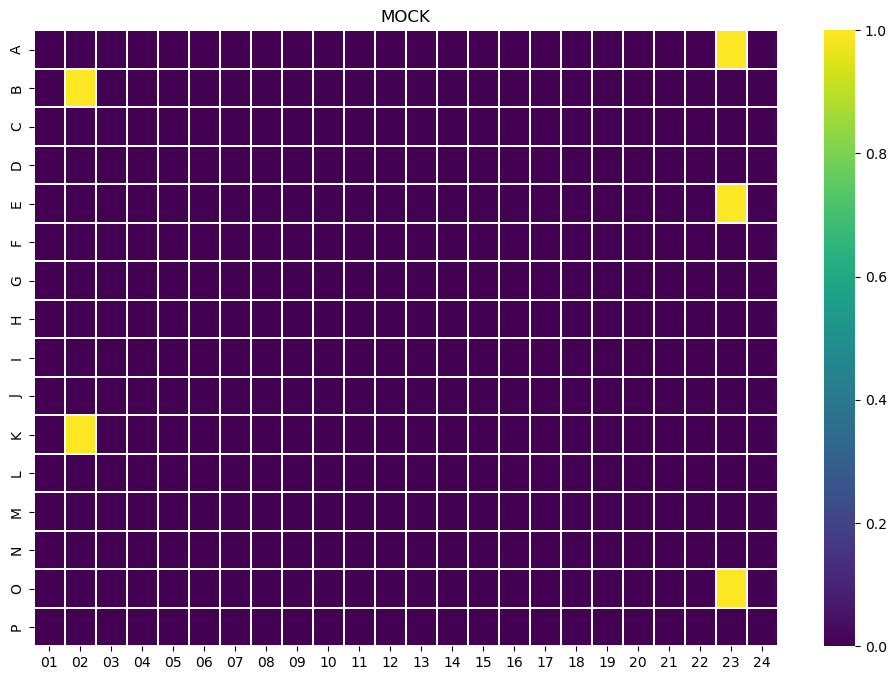

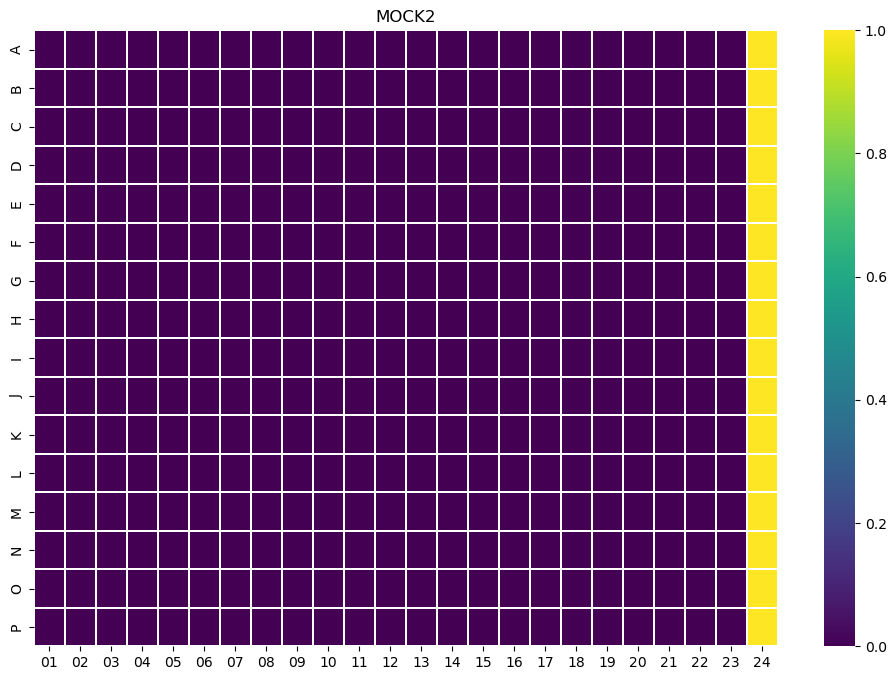

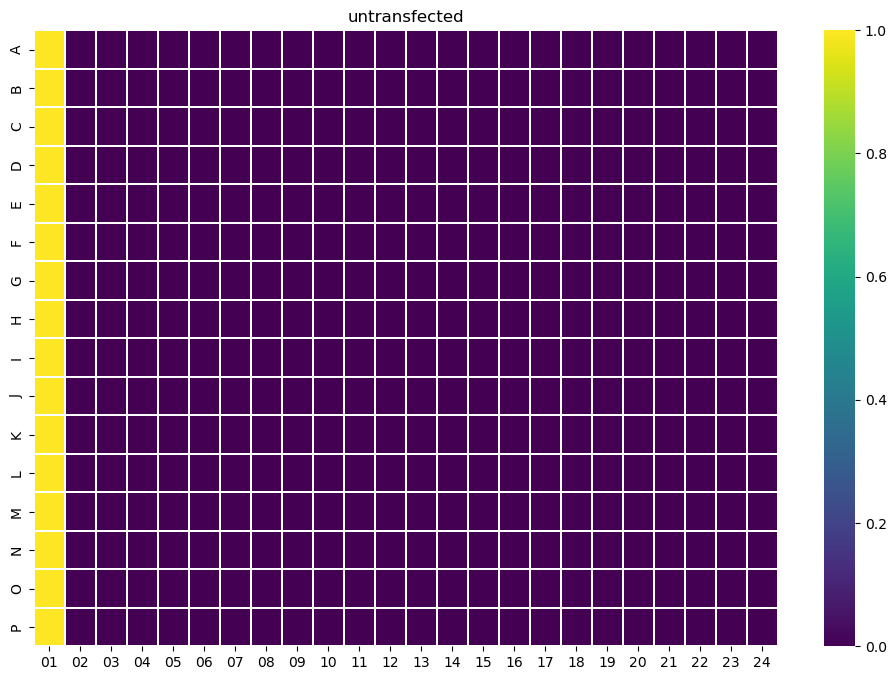

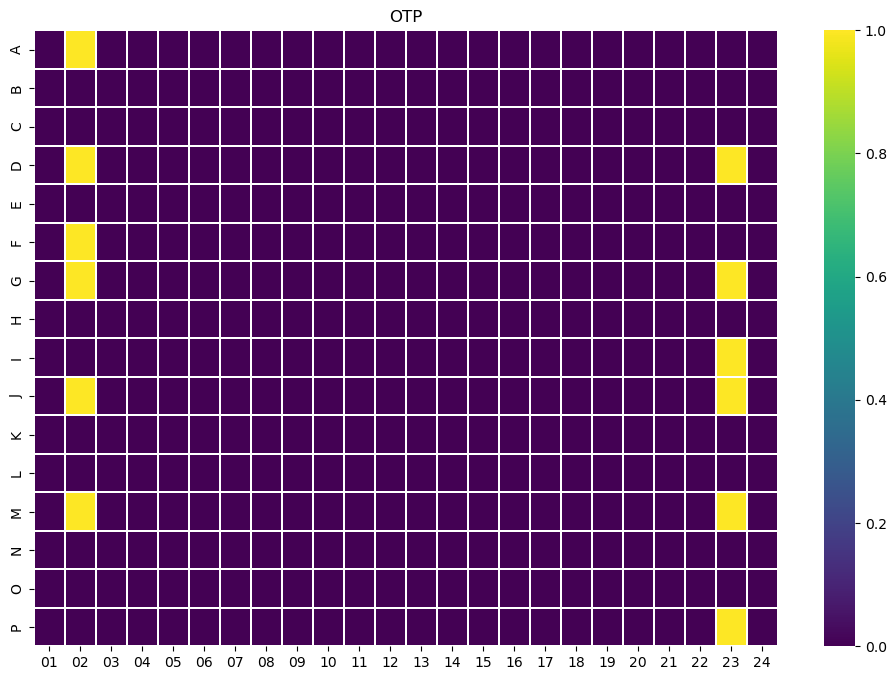

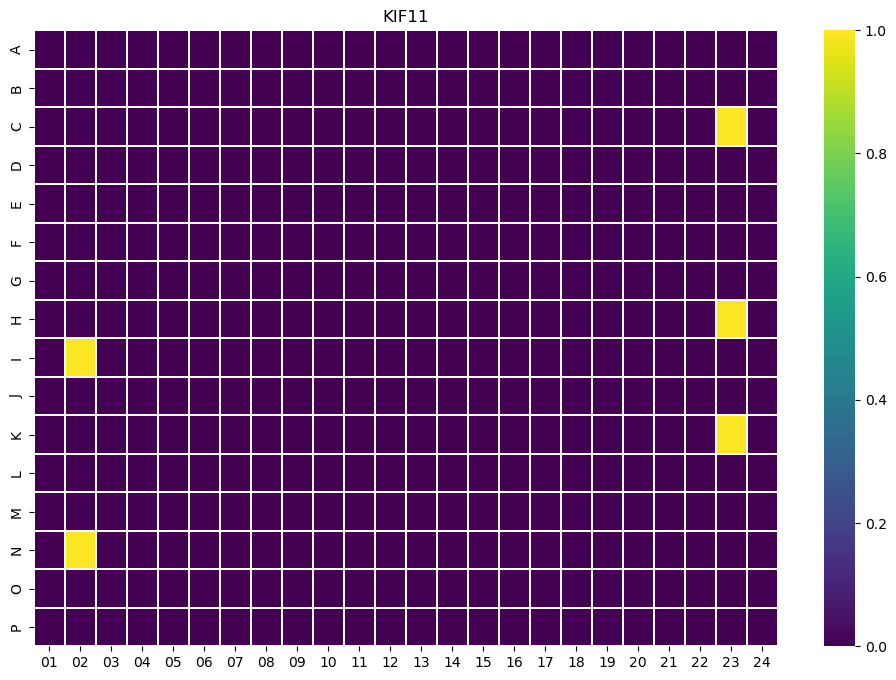

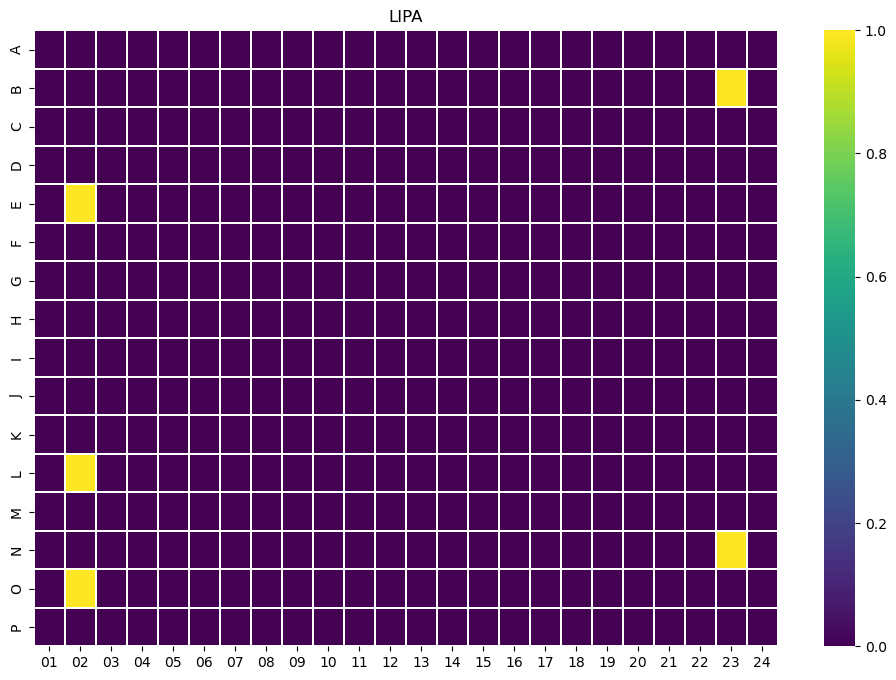

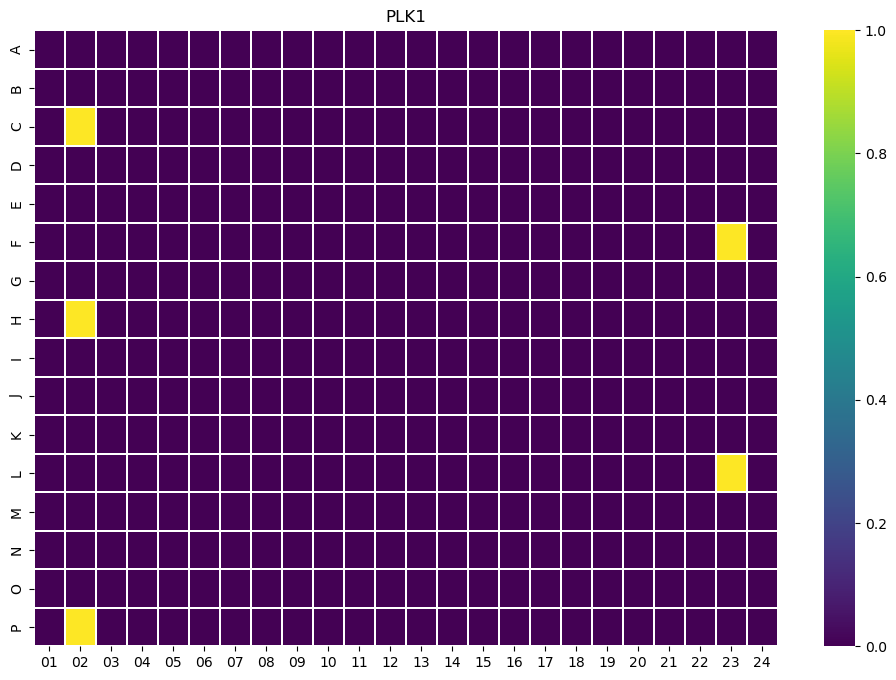

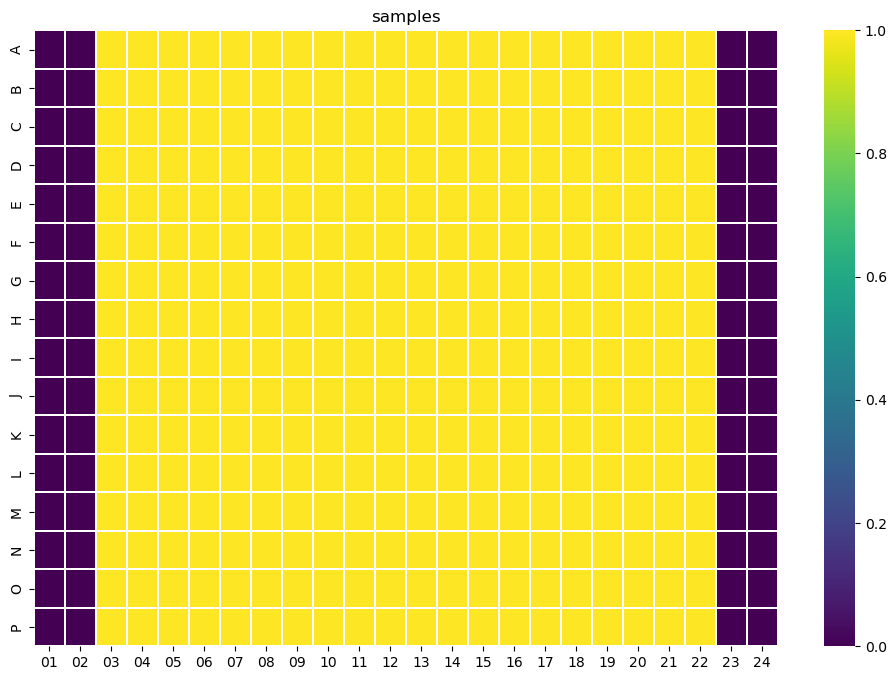

In [8]:
## This cell is important for defining control and sample columns
##necessary for plots

import numpy as np
import pandas as pd
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']



### Mock ##########################################
zero_data = np.zeros(shape=(16,24))
mock = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)
#mock_list_r = !cat control.txt | grep mock | cut -f 1 | cut -b 1
mock_list_r = []
mock_list_c = []

with open("control.txt", "r") as file:
    for line in file:
        if "mock" in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                mock_list_r.append(first_field[1:4])
                mock_list_c.append(first_field[0])

for c,r in zip(mock_list_c,mock_list_r):
    mock.loc[c, r] = 1

plt.figure(figsize=(12,8))
sns.heatmap(np.array(mock),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('MOCK')



### Mock 2 ###################################
zero_data = np.zeros(shape=(16,24))
mock2 = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)

mock2_list_r = []
mock2_list_c = []

with open("control.txt", "r") as file:
    for line in file:
        if "Mock2" in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                mock2_list_r.append(first_field[1:4])
                mock2_list_c.append(first_field[0])


for c,r in zip(mock2_list_c,mock2_list_r):
    mock2.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(mock2),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('MOCK2')
##################################################

#### unstransfected wells ########################
untr_list_r = []
untr_list_c = []
zero_data = np.zeros(shape=(16,24))
untr = pd.DataFrame(zero_data,columns=column_number,index=row_number,dtype=int)
with open ("control.txt","r") as file:
    for line in file:
        if 'untransfected' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                untr_list_c.append(first_field[0])
                untr_list_r.append(first_field[1:4])

for c,r in zip(untr_list_c,untr_list_r):
    untr.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(untr),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('untransfected')

###################################################
###############OTP ###############################

zero_data = np.zeros(shape=(16,24))
OTP = pd.DataFrame(zero_data,columns=column_number,index=row_number)
OTP_list_r = []
OTP_list_c = []

with open ("control.txt","r") as file:
    for line in file:
        if 'OTP' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                OTP_list_c.append(first_field[0])
                OTP_list_r.append(first_field[1:4])


for c,r in zip(OTP_list_c,OTP_list_r):
    OTP.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(OTP),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('OTP')



#################### KIF11 ######################
KIF11_list_c = []
KIF11_list_r = []

zero_data = np.zeros(shape=(16,24))
KIF11 = pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'KIF11' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                KIF11_list_c.append(first_field[0])
                KIF11_list_r.append(first_field[1:4])



for c,r in zip(KIF11_list_c,KIF11_list_r):
    KIF11.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(KIF11),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('KIF11')
  
###############################################
# #######################LIPA #################  
LIPA_list_r = []
LIPA_list_c = []
zero_data = np.zeros(shape=(16,24))
LIPA=pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'LIPA' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                LIPA_list_c.append(first_field[0])
                LIPA_list_r.append(first_field[1:4])   

for c,r in zip(LIPA_list_c,LIPA_list_r):
    LIPA.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(LIPA),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('LIPA')
###############################################
####################### PLK1 ##################
PLK1_list_c=[]
PLK1_list_r=[]
zero_data = np.zeros(shape=(16,24))
PLK1=pd.DataFrame(zero_data,columns=column_number,index=row_number)
with open ("control.txt","r") as file:
    for line in file:
        if 'PLK1' in line:
            first_field = line.strip().split('\t')[0]
            if first_field:
                PLK1_list_c.append(first_field[0])
                PLK1_list_r.append(first_field[1:4])
for c,r in zip(PLK1_list_c,PLK1_list_r):
    PLK1.loc[c,r] = 1
plt.figure(figsize=(12,8))
sns.heatmap(np.array(PLK1),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('PLK1')

###############################################

zero_data = np.ones(shape=(16,24))
wells=pd.DataFrame(zero_data,columns=column_number,index=row_number)
samples = wells-mock-mock2-LIPA-KIF11-OTP-untr-PLK1

plt.figure(figsize=(12,8))
sns.heatmap(np.array(samples),cmap='viridis',linewidths=0.2,xticklabels=column_number,yticklabels=row_number)
plt.title('samples')




The next cell is important for plate Number
Always run before each plot

### Don't run the next cell
It is for creating count or area matrix
run only if you do not have .json files and want to create from .csv file

Other wise DO NOT run

In [11]:
plateNr = ! ls csv_files/B/4field/*.csv | cut -d '_' -f 3 | sed s/'.csv'/''/g
plateNr

['170719230001', '170720050001', '170720100001']

In [12]:
# this is for number of cells
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']

#Create empty list
my_dict_cellNr = {}

# Access the value using the key
#my_dict_cellNr["170524210001"] 
for p in plateNr:
    print(p)
    temp_df = pd.read_csv('csv_files/B/4field/MFGTMPcx7_'+p+'.csv')
    new_df_cell_number = pd.DataFrame(columns=column_number,index=row_number)
    for r in row_number:
        for c in column_number:
            well = r+c
            new_df_cell_number.loc[r][c] = len(temp_df[temp_df['Image_name'].str.contains(p+'_'+well)]['Area']) #len function counts cells
    my_dict_cellNr[p]=new_df_cell_number


170719230001
170720050001
170720100001


### Don't run the next cell
It is for saving .json files of _count or _area
run only if you do not have .json files and want to create from .csv file run it after previous cell

In [13]:
# Saves dictionaries in json files, remove names of plates you already have jsons for in cell above before running
import json
for k in my_dict_cellNr.keys():
    json.dump(my_dict_cellNr[k].to_json(orient='split'), open('csv_files/B/4field/'+k+'_count.json', 'w'))
    

### Run the following cell if you are going to plot _count plots (raw and normalized)

In [9]:
Barcode_B    = [ba for ba in barcode_plate['Barcode'] if ba.endswith('B')]
Barcode_B  


['20170516-SA-12022-01B',
 '20170516-SA-12023-02B',
 '20170516-SA-12024-03B',
 '20170516-SA-12025-04B',
 '20170522-SA-12026-05B',
 '20170522-SA-12027-06B',
 '20170522-SA-12028-07B',
 '20170522-SA-12029-08B',
 '20170523-SA-12030-09B',
 '20170523-SA-12031-10B',
 '20170523-SA-12032-11B',
 '20170529-SA-12034-13B',
 '20170529-SA-12035-14B',
 '20170529-SA-12036-15B',
 '20170530-SA-12038-17B',
 '20170530-SA-12039-18B',
 '20170530-SA-12040-19B',
 '20170613-SA-12050-29B',
 '20170613-SA-12051-30B',
 '20170613-SA-12052-31B',
 '20170614-SA-12054-33B',
 '20170614-SA-12055-34B',
 '20170614-SA-12056-35B',
 '20170614-SA-12057-36B',
 '20170619-SA-12058-37B',
 '20170619-SA-12001-38B',
 '20170619-SA-12002-39B',
 '20170626-SA-12008-45B',
 '20170626-SA-12009-46B',
 '20170626-SA-12010-47B',
 '20170626-SA-12011-48B',
 '20170627-SA-12012-49B',
 '20170703-SA-12016-53B',
 '20170703-SA-12017-54B',
 '20170703-SA-12018-55B',
 '20170704-SA-12020-57B',
 '20170704-SA-12021-58B',
 '20170704-SA-12042-59B',
 '20170704-S

C:\Users\salma\AppData\Local\Temp\ipykernel_11692\1113690472.py:59: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


58


C:\Users\salma\AppData\Local\Temp\ipykernel_11692\1113690472.py:174: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(label_X, rotation=90)


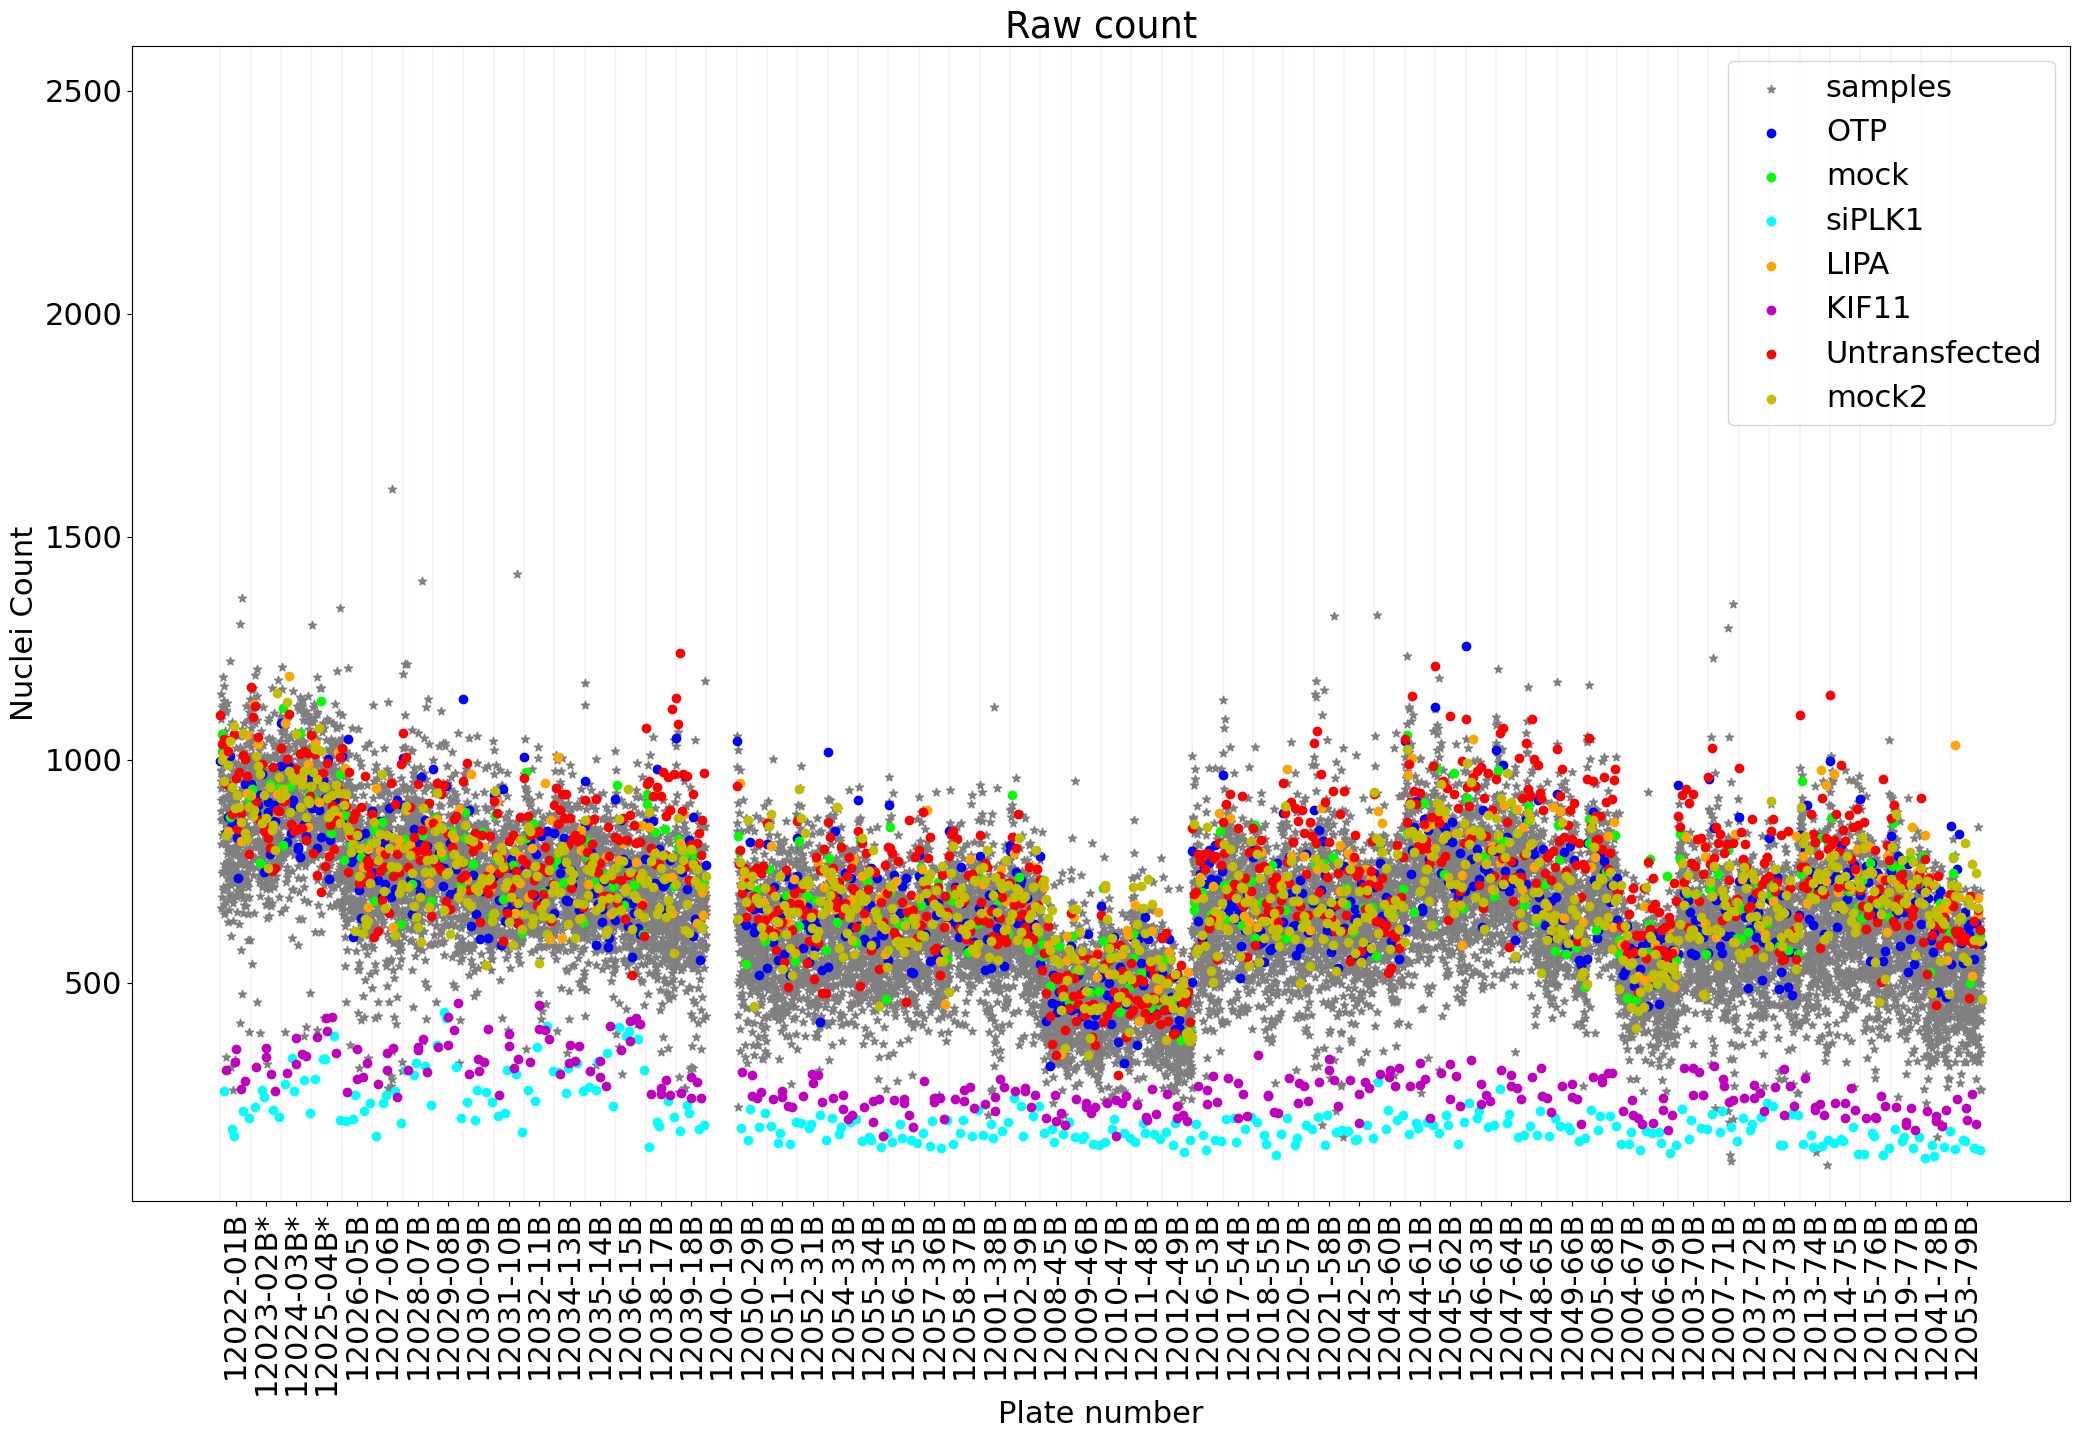

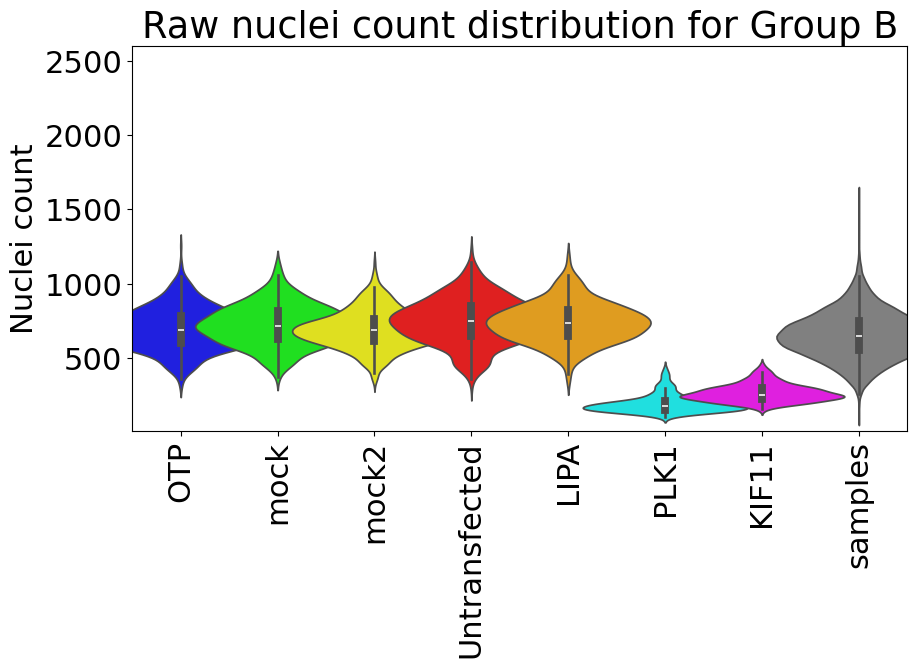

In [11]:
#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np
import os

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_B:
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]

    if len(pl) != 0:
        with open('csv_files/B/'+pl.replace('MFGTMPcx7_','')+'_count.json','r') as f:
        
        ###Normalizing to avg of OTP wells
            json_str   = json.load(f)
            json_dict  = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
             ##OTP


            ## This whole part is for adding 4 more field##
            P_ID  = pl
            
            ff =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
            fourfields = 'csv_files/B/4field/'+ff.replace('MFGTMPcx7_','')+'_count.json'
            if os.path.exists(fourfields):
                with open(fourfields,'r') as f:
                    second_json_4fields = json.load(f)
                    second_json_dict_4fields = json.loads(second_json_4fields)


                    second_plate_data = np.array(second_json_dict_4fields['data'])
                    plate_data = (plate_data+second_plate_data)*0.8


    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    plate_data = plate_data


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)
      
            

          
    

#label_X= plateNr
print(len(label_X))
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_B)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei Count')
plt.rcParams.update({'font.size': 22})
plt.ylim([10,2600])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Raw count')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)
plt.ylabel('Nuclei count')
plt.title('Raw nuclei count distribution for Group B')
plt.ylim([10,2600])


np.save('B_count.npy',all_plate_for_plot,allow_pickle=True)

C:\Users\salma\AppData\Local\Temp\ipykernel_11692\182913298.py:58: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


58


C:\Users\salma\AppData\Local\Temp\ipykernel_11692\182913298.py:173: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(label_X, rotation=90)


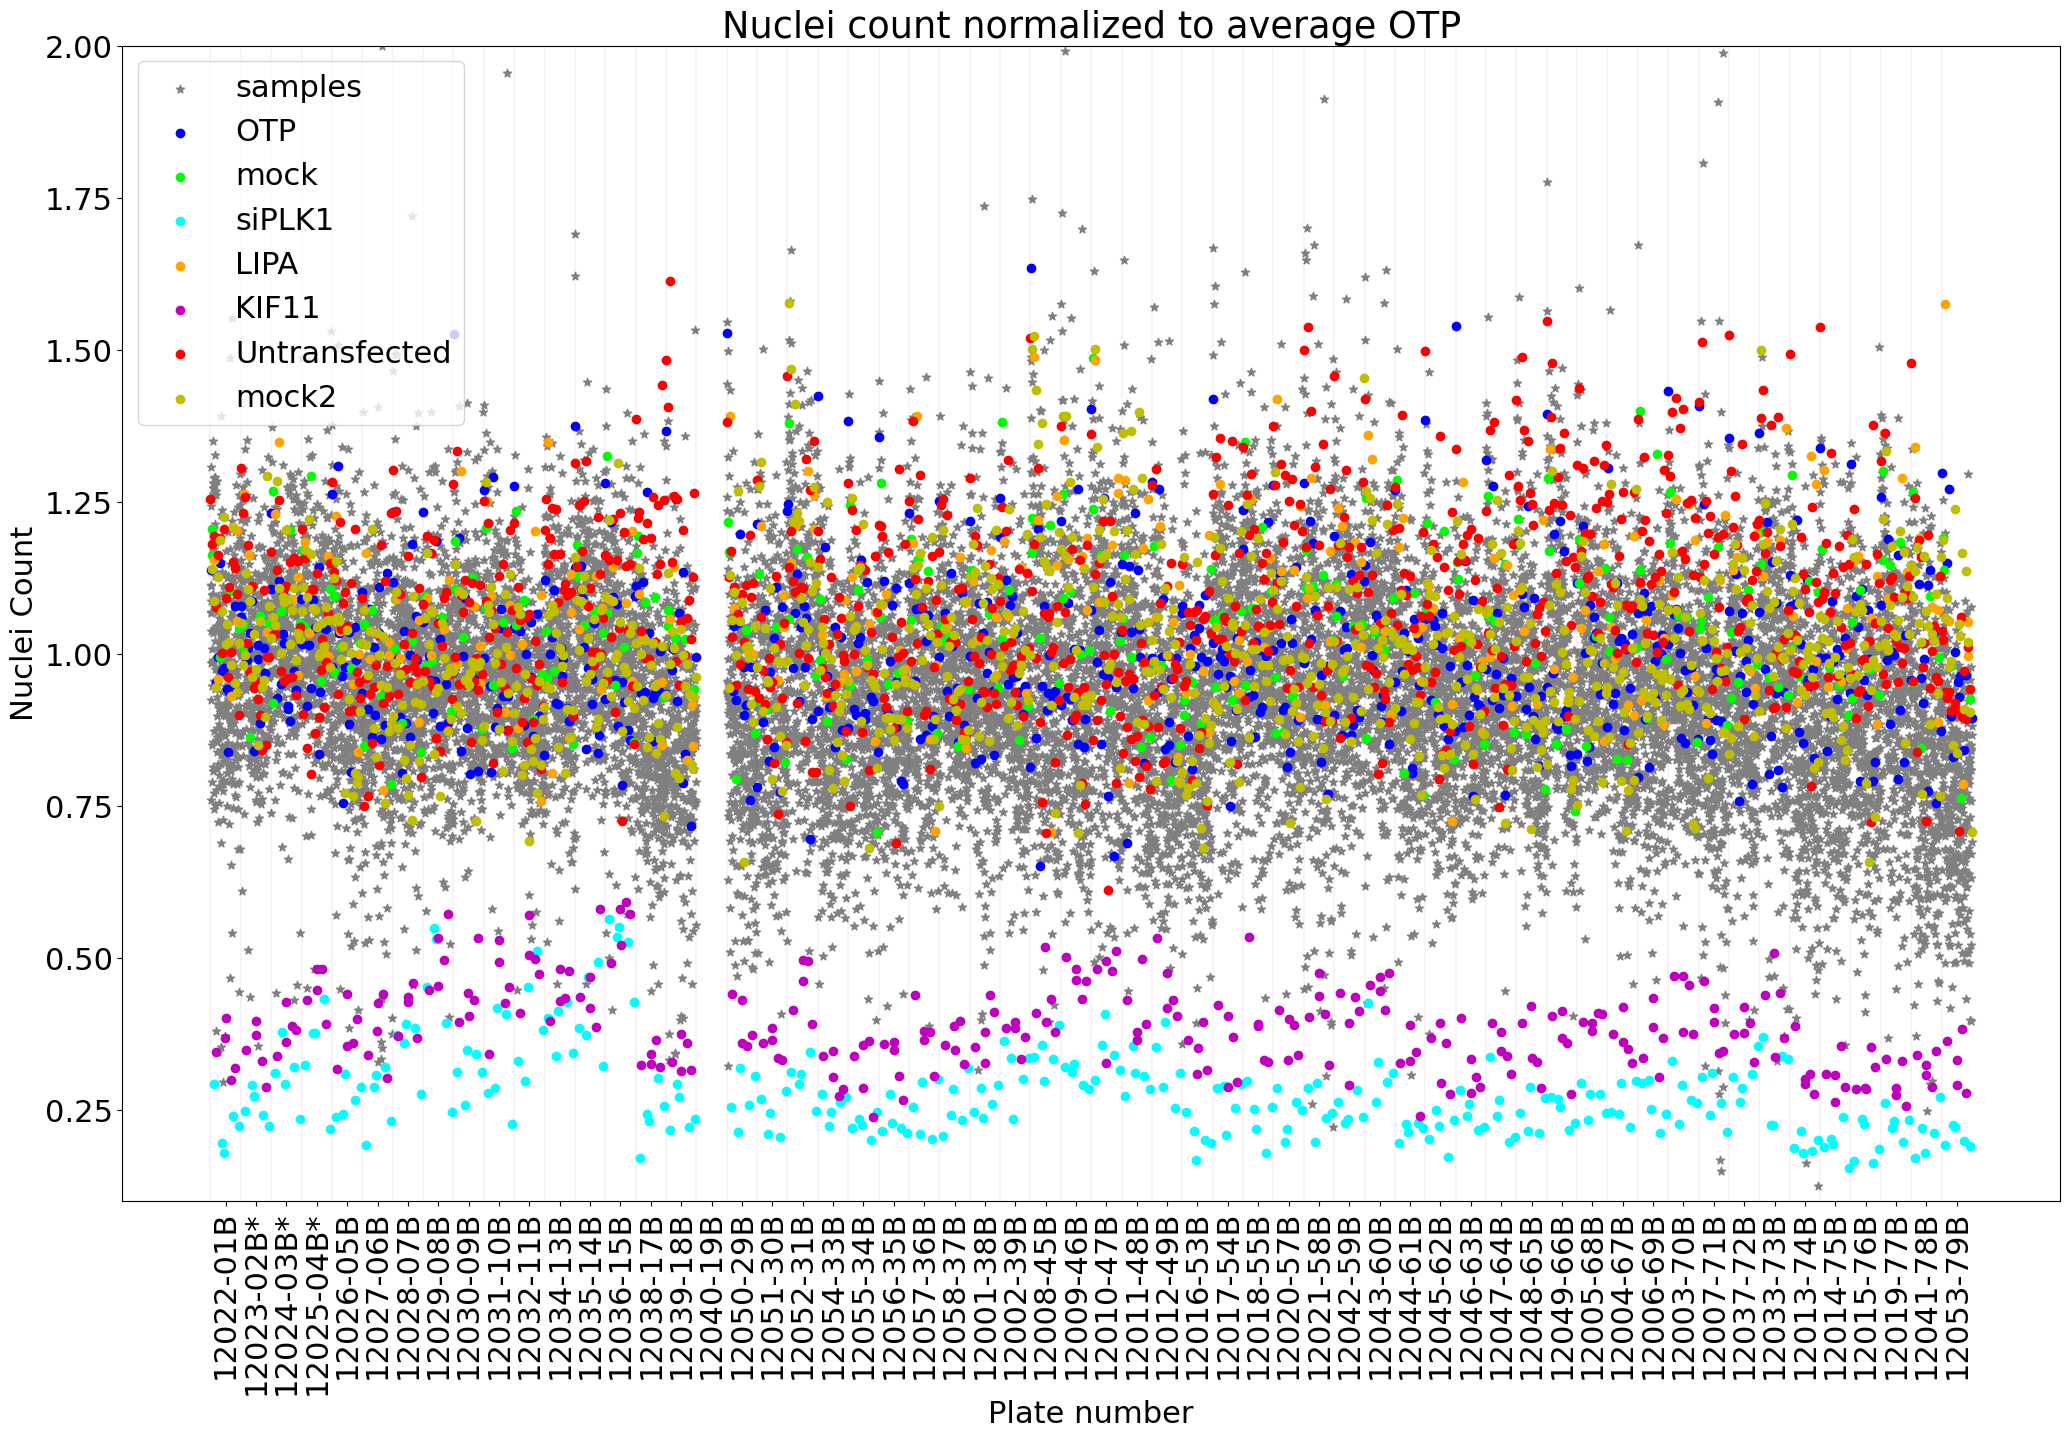

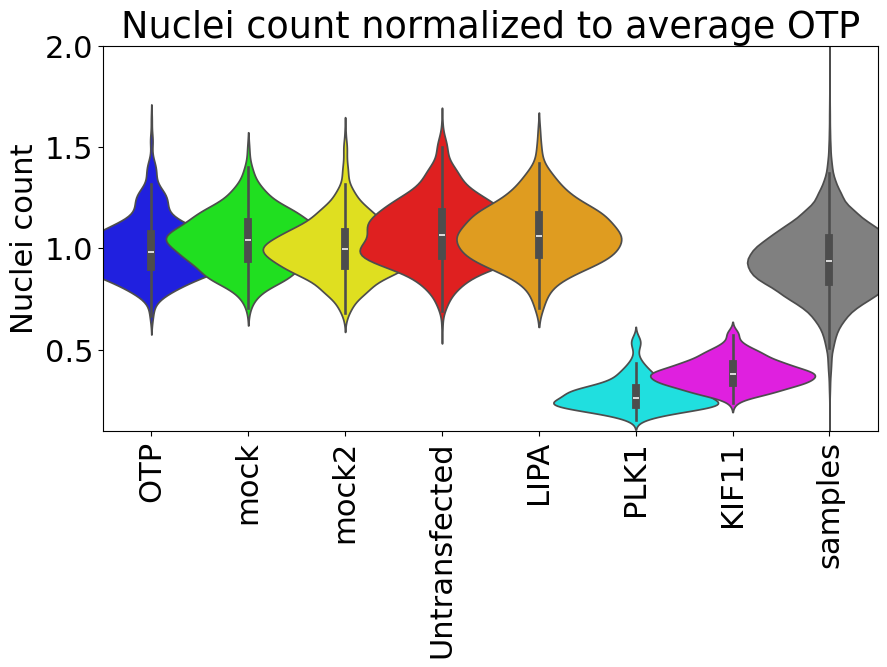

In [12]:
#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np
import os

#make all jsonfiles into keys


#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_B:
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/B/'+pl.replace('MFGTMPcx7_','')+'_count.json','r') as f:
        
        ###Normalizing to avg of OTP wells
            json_str   = json.load(f)
            json_dict  = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
             ##OTP


            ## This whole part is for adding 4 more field##
            P_ID  = pl
           
            ff =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
            fourfields = 'csv_files/B/4field/'+ff.replace('MFGTMPcx7_','')+'_count.json'
            if os.path.exists(fourfields):
                with open(fourfields,'r') as f:
                    second_json_4fields = json.load(f)
                    second_json_dict_4fields = json.loads(second_json_4fields)


                    second_plate_data = np.array(second_json_dict_4fields['data'])
                    plate_data = (plate_data+second_plate_data)*0.8


    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)
      
            

          
    

#label_X= plateNr
print(len(label_X))
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_B)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei Count')
plt.rcParams.update({'font.size': 22})
plt.ylim([0.1,2])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Nuclei count normalized to average OTP')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)

plt.ylim([0.1,2])

plt.ylabel('Nuclei count')
plt.title('Nuclei count normalized to average OTP')

np.save('B_normalized_count.npy',all_plate_for_plot,allow_pickle=True)


### Combine Nuclei count with four fields

In the following cells we first merge main plates with 4 field plates and then normalize them

In [19]:
plateNr = !ls csv_files/B/*.csv  | sed s/'.csv'/''/g 
plateNr

['csv_files/B/MFGTMPcx7_170521170001',
 'csv_files/B/MFGTMPcx7_170522120001',
 'csv_files/B/MFGTMPcx7_170523070001',
 'csv_files/B/MFGTMPcx7_170524170002',
 'csv_files/B/MFGTMPcx7_170525230001',
 'csv_files/B/MFGTMPcx7_170526180001',
 'csv_files/B/MFGTMPcx7_170527140001',
 'csv_files/B/MFGTMPcx7_170528090001',
 'csv_files/B/MFGTMPcx7_170529170001',
 'csv_files/B/MFGTMPcx7_170530150001',
 'csv_files/B/MFGTMPcx7_170531100001',
 'csv_files/B/MFGTMPcx7_170602010001',
 'csv_files/B/MFGTMPcx7_170602210001',
 'csv_files/B/MFGTMPcx7_170605200001',
 'csv_files/B/MFGTMPcx7_170607100001',
 'csv_files/B/MFGTMPcx7_170608160001',
 'csv_files/B/MFGTMPcx7_170618100001',
 'csv_files/B/MFGTMPcx7_170619050001',
 'csv_files/B/MFGTMPcx7_170620000001',
 'csv_files/B/MFGTMPcx7_170621150001',
 'csv_files/B/MFGTMPcx7_170622110001',
 'csv_files/B/MFGTMPcx7_170623060001',
 'csv_files/B/MFGTMPcx7_170624010001',
 'csv_files/B/MFGTMPcx7_170624200001',
 'csv_files/B/MFGTMPcx7_170625150001',
 'csv_files/B/MFGTMPcx7_1

#### The following cell is for creating _combined_area from combined .csv files of main plates with 4 fields
## DO not run it if you already have _combined_4fields.json files

In [21]:
#COPY for cell mean area
row_number = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P']
column_number = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18','19','20','21','22','23','24']

#Create empty list
my_dict_cellSize = {}

# Access the value using the key
#my_dict_cellSize["MFGTMPcx7_170524210001"] 
for p in plateNr:
    temp_df_size = pd.read_csv(p+'.csv')
    P_ID   = p.split('/B/')[1]
    print(P_ID)
    
    fourfields =barcode_plate.loc[barcode_plate['Plate']==P_ID, '4fields'].values[0]
    
    
    if len(fourfields):
        print(fourfields,'yesss')
        second_df  = pd.read_csv('csv_files/B/4field/'+fourfields+'.csv')
        merged_df_size = pd.concat([temp_df_size, second_df], axis=0)
            
        temp_df_size = merged_df_size         
    
   
    new_df_cell_mean_area = pd.DataFrame(columns=column_number,index=row_number)
    for r in row_number:
        for c in column_number:
            well = r+c
            new_df_cell_mean_area.loc[r][c] = np.mean(temp_df_size[temp_df_size['Image_name'].str.contains('_'+well)]['Area']) #switched pattern to well
    my_dict_cellSize[p]=new_df_cell_mean_area


MFGTMPcx7_170521170001
MFGTMPcx7_170719230001 yesss
MFGTMPcx7_170522120001
MFGTMPcx7_170720050001 yesss
MFGTMPcx7_170523070001
MFGTMPcx7_170720100001 yesss
MFGTMPcx7_170524170002
MFGTMPcx7_170525230001
MFGTMPcx7_170526180001
MFGTMPcx7_170527140001
MFGTMPcx7_170528090001
MFGTMPcx7_170529170001
MFGTMPcx7_170530150001
MFGTMPcx7_170531100001
MFGTMPcx7_170602010001
MFGTMPcx7_170602210001
MFGTMPcx7_170605200001
MFGTMPcx7_170607100001
MFGTMPcx7_170608160001
MFGTMPcx7_170618100001
MFGTMPcx7_170619050001
MFGTMPcx7_170620000001
MFGTMPcx7_170621150001
MFGTMPcx7_170622110001
MFGTMPcx7_170623060001
MFGTMPcx7_170624010001
MFGTMPcx7_170624200001
MFGTMPcx7_170625150001
MFGTMPcx7_170626110001
MFGTMPcx7_170702000001
MFGTMPcx7_170702190001
MFGTMPcx7_170703170001
MFGTMPcx7_170704130001
MFGTMPcx7_170706050001
MFGTMPcx7_170708230001
MFGTMPcx7_170709180001
MFGTMPcx7_170710130003
MFGTMPcx7_170712030001
MFGTMPcx7_170713090001
MFGTMPcx7_170714050001
MFGTMPcx7_170715020001
MFGTMPcx7_170715210001
MFGTMPcx7_170716

In [22]:
# Saves dictionaries in json files, remove names of plates you already have jsons for in cell above before running
import json
for k in my_dict_cellSize.keys():
    json.dump(my_dict_cellSize[k].to_json(orient='split'), open(k.replace('MFGTMPcx7_','')+'_area_combined_4fields.json', 'w'))

### Normalize and merge 4fields for those plates that has 4 more fields for object area

In [13]:
Barcode_B    = [ba for ba in barcode_plate['Barcode'] if ba.endswith('B')]
Barcode_B  


['20170516-SA-12022-01B',
 '20170516-SA-12023-02B',
 '20170516-SA-12024-03B',
 '20170516-SA-12025-04B',
 '20170522-SA-12026-05B',
 '20170522-SA-12027-06B',
 '20170522-SA-12028-07B',
 '20170522-SA-12029-08B',
 '20170523-SA-12030-09B',
 '20170523-SA-12031-10B',
 '20170523-SA-12032-11B',
 '20170529-SA-12034-13B',
 '20170529-SA-12035-14B',
 '20170529-SA-12036-15B',
 '20170530-SA-12038-17B',
 '20170530-SA-12039-18B',
 '20170530-SA-12040-19B',
 '20170613-SA-12050-29B',
 '20170613-SA-12051-30B',
 '20170613-SA-12052-31B',
 '20170614-SA-12054-33B',
 '20170614-SA-12055-34B',
 '20170614-SA-12056-35B',
 '20170614-SA-12057-36B',
 '20170619-SA-12058-37B',
 '20170619-SA-12001-38B',
 '20170619-SA-12002-39B',
 '20170626-SA-12008-45B',
 '20170626-SA-12009-46B',
 '20170626-SA-12010-47B',
 '20170626-SA-12011-48B',
 '20170627-SA-12012-49B',
 '20170703-SA-12016-53B',
 '20170703-SA-12017-54B',
 '20170703-SA-12018-55B',
 '20170704-SA-12020-57B',
 '20170704-SA-12021-58B',
 '20170704-SA-12042-59B',
 '20170704-S

C:\Users\salma\AppData\Local\Temp\ipykernel_11692\688998755.py:43: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\salma\AppData\Local\Temp\ipykernel_11692\688998755.py:160: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(label_X, rotation=90)


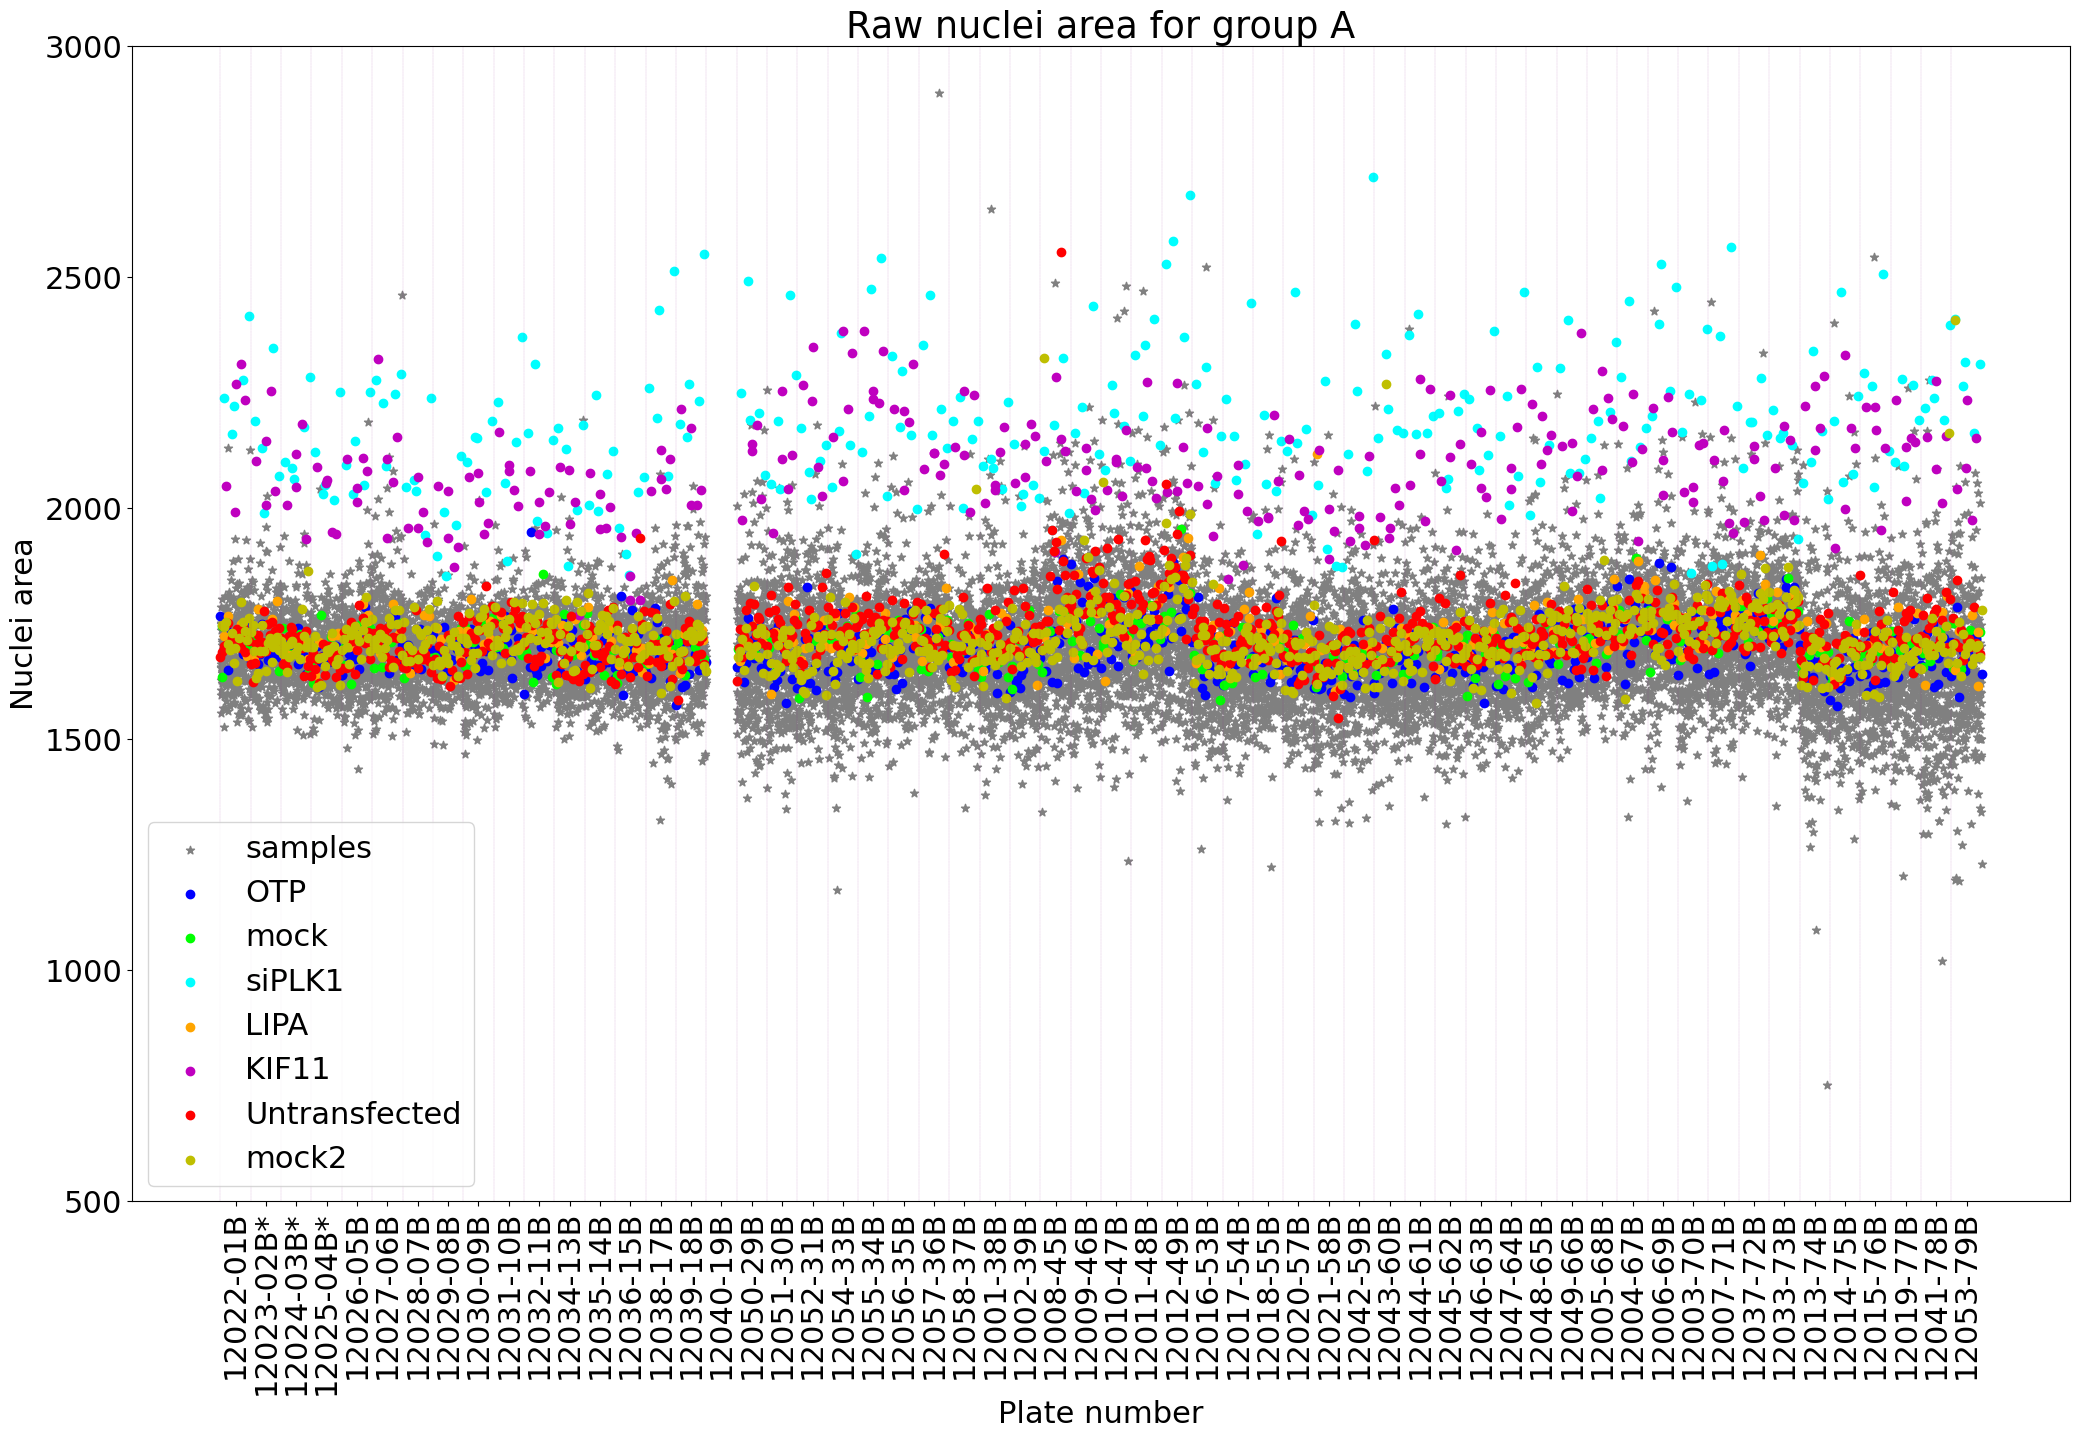

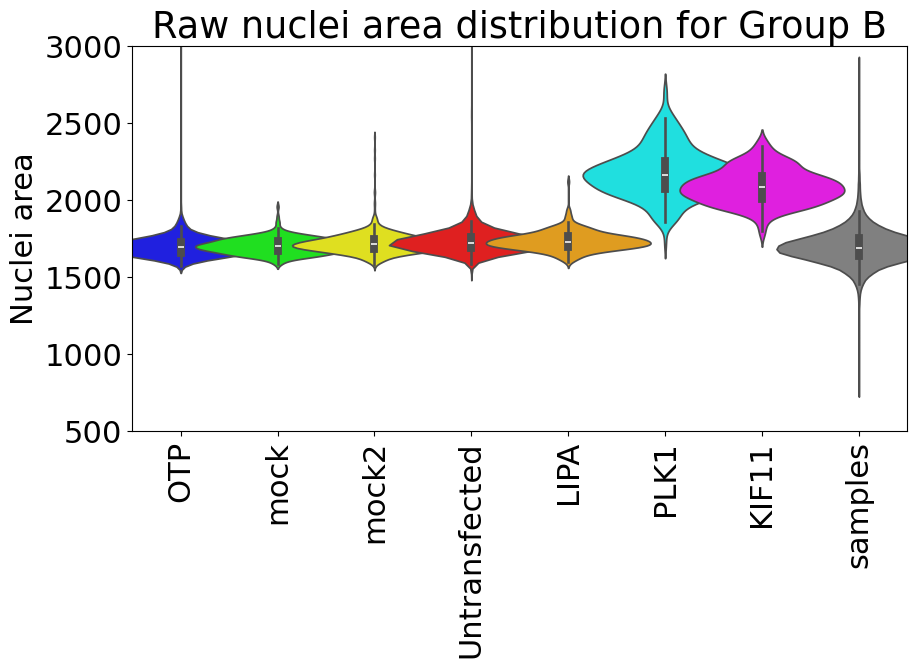

In [14]:
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np

#make all jsonfiles into keys



#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_B:
            
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/B/'+pl.replace('MFGTMPcx7_','')+'_area_combined_4fields.json','r') as f:
        
            json_str = json.load(f)
            json_dict = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
        
         ##OTP

    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    #print(otp_avg)
    #plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)

        
       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_B)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')

X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)


#for k in keys_json:
    #label_X.append(k.replace('_count.json','').replace('CSV/A/',''))
#for k in Barcode:
#    label_X.append(k)
    

#label_X= plateNr
#print(len(label_X))
ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei area')
plt.rcParams.update({'font.size': 22})
plt.ylim([500,3000])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Raw nuclei area for group A')


fig, ax2 = plt.subplots(1,1,figsize=(10,5))

sns.violinplot([OTP_for_plot[OTP_for_plot>0],mock_for_plot[mock_for_plot>0],
                mock2_for_plot[mock2_for_plot>0],untr_for_plot[untr_for_plot>0],LIPA_for_plot[LIPA_for_plot>0],
                PLK1_for_plot[PLK1_for_plot>0],
                KIF11_for_plot[KIF11_for_plot>0],all_for_plot[all_for_plot>0]],
                palette=['blue','lime','yellow','red','orange','cyan','magenta','gray'],width=1.7)
label_X = ['OTP','mock','mock2','Untransfected','LIPA','PLK1','KIF11','samples']
ax2.set_xticklabels(label_X, rotation=90)
plt.ylabel('Nuclei area')
plt.title('Raw nuclei area distribution for Group B')
plt.ylim([500,3000])


np.save('B_area.npy',all_plate_for_plot,allow_pickle=True)

C:\Users\salma\AppData\Local\Temp\ipykernel_11692\2226660376.py:48: RuntimeWarning: Mean of empty slice.
  otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
c:\Users\salma\.conda\envs\SalmaEnv\envs\coderefinery\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


58


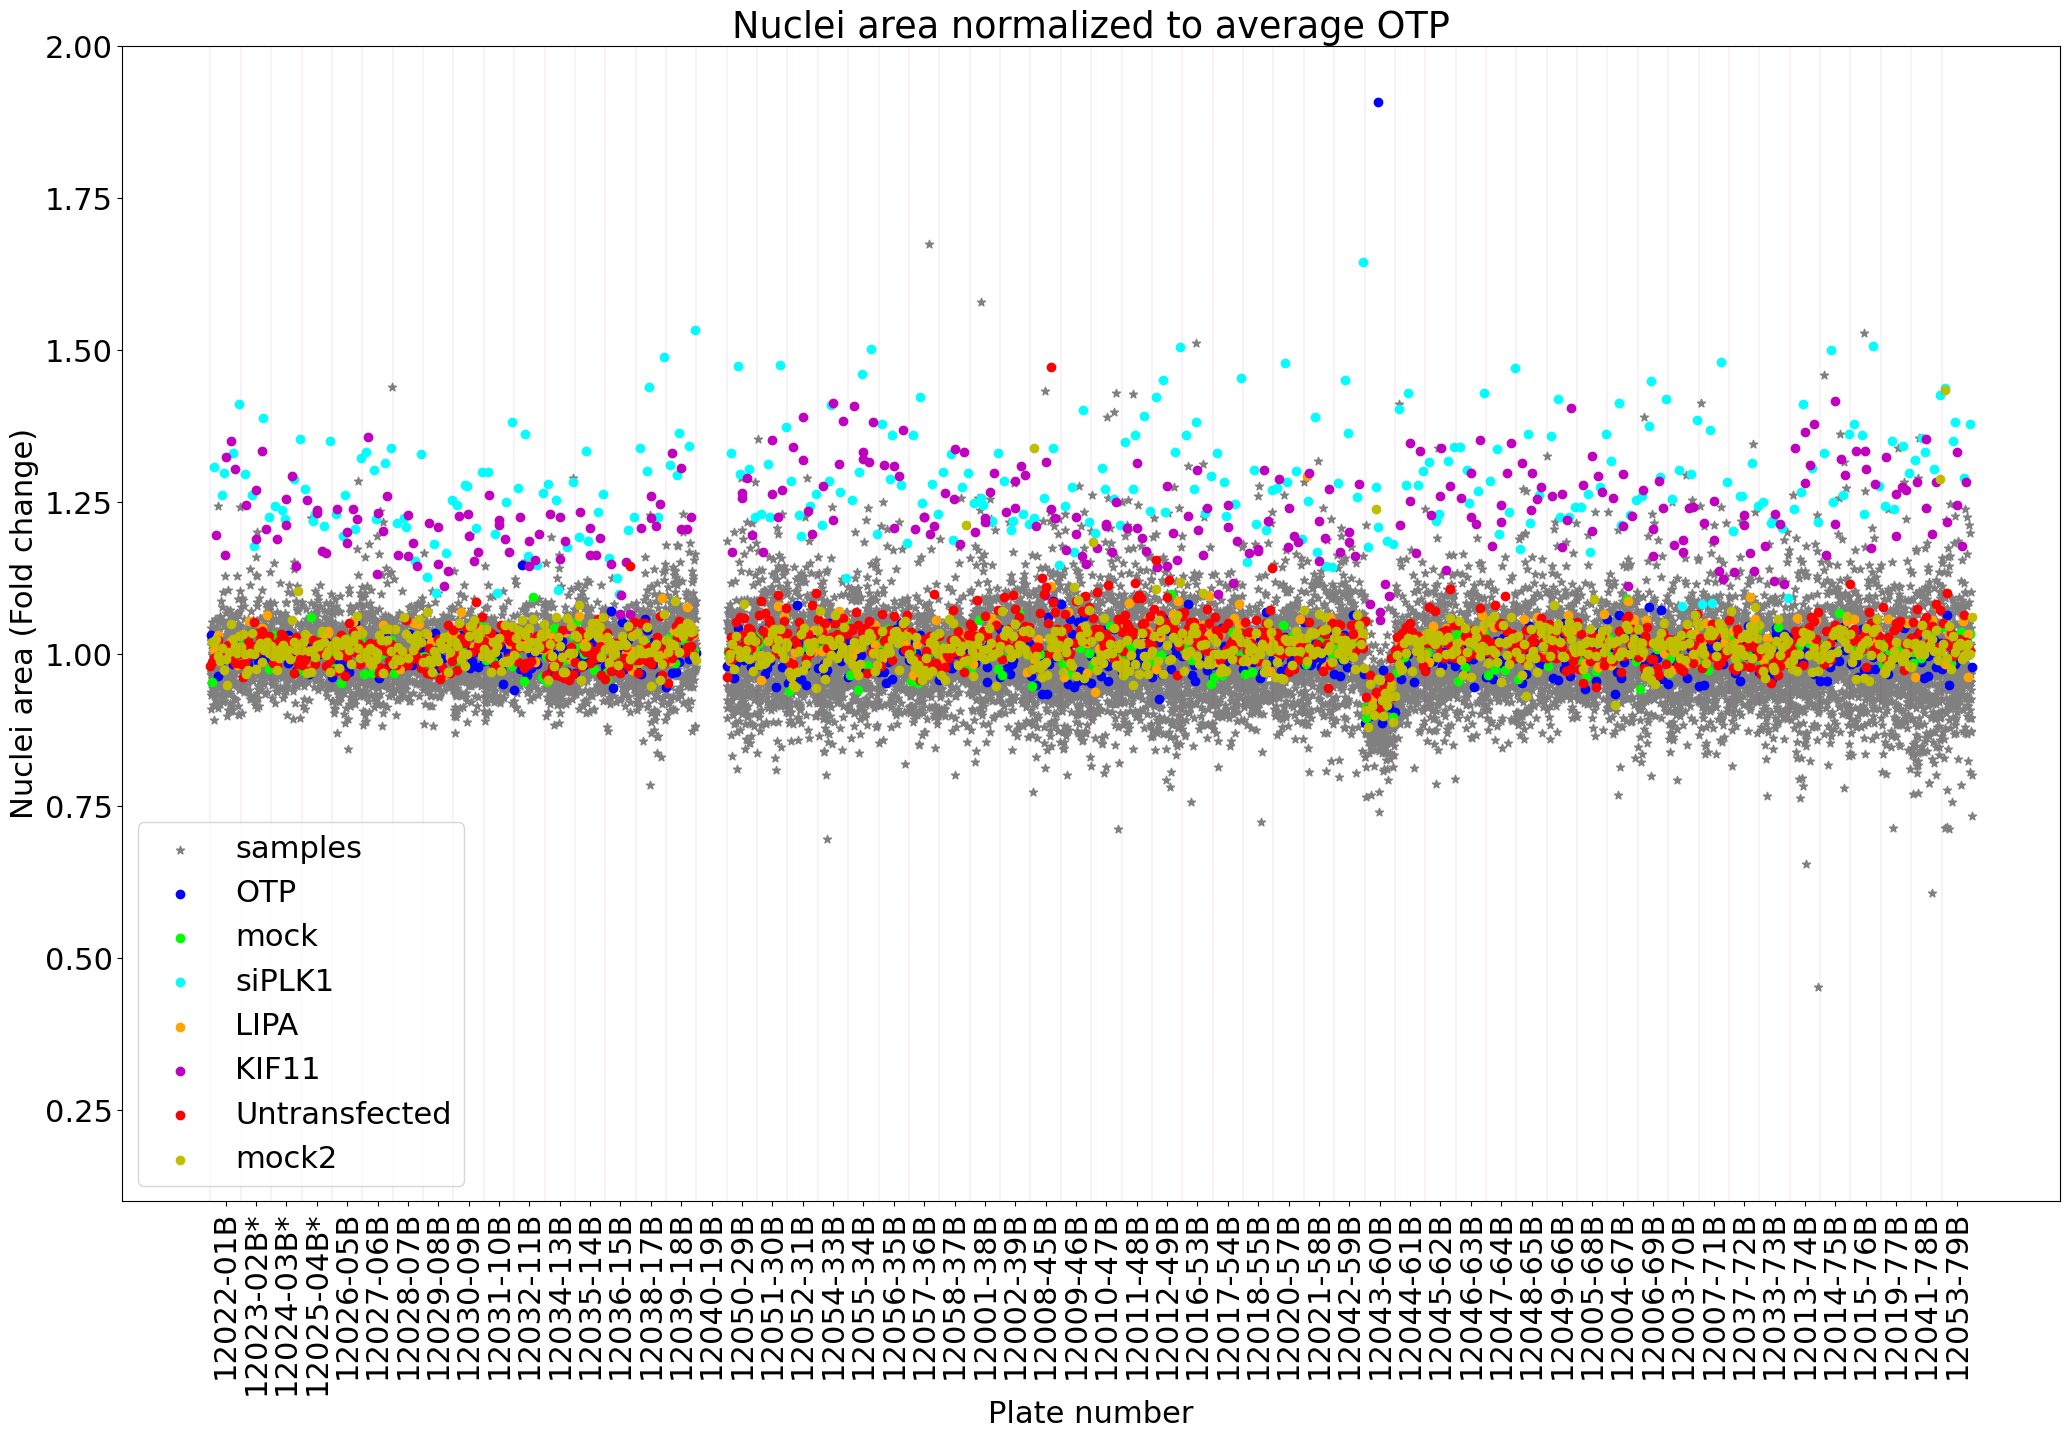

In [15]:

#COPY
# Reads saved json files

#import json so you dont have to run above cell if no new files needs saving
import json
import numpy as np

#make all jsonfiles into keys



#create empty list
l = []
mock_well = []
OTP_well  = []
KIF11_well =[]
LIPA_well = []
PLK1_well = []
mock2_well= []
untr_well = []
label_X = []
all_plate_well = []

#loop through all keys (jsonfiles), load, add key to the empty list l
for k in Barcode_B:
            
    f4 = barcode_plate.loc[barcode_plate['Barcode']==k,'4fields'].values[0]
    lb = k.split('-SA-')[1]+str((bool(f4))).replace('True','*').replace('False','')
    label_X.append(lb)
    
    plate_data = np.zeros([16,24])
    pl   = barcode_plate.loc[barcode_plate['Barcode']==k, 'Plate'].values[0]
   
    if len(pl) != 0:
        with open('csv_files/B/'+pl.replace('MFGTMPcx7_','')+'_area_combined_4fields.json','r') as f:
        
       
        
            json_str = json.load(f)
            json_dict = json.loads(json_str)
            plate_data = np.array(json_dict['data'])
        
        
        
         ##OTP

    OTP_per_plate =plate_data *np.array(OTP)
    otp_avg =  OTP_per_plate[np.nonzero(OTP_per_plate)].mean()
    #print(otp_avg)
    plate_data = plate_data/otp_avg


    ##samples
    l.append(plate_data*np.array(samples))

    ##controls
    mock_well.append(plate_data*np.array(mock))
    OTP_well.append(plate_data*np.array(OTP))
    KIF11_well.append(plate_data*np.array(KIF11))
    LIPA_well.append(plate_data*np.array(LIPA))
    PLK1_well.append(plate_data*np.array(PLK1))
    mock2_well.append(plate_data*np.array(mock2))
    untr_well.append(plate_data*np.array(untr))

    all_plate_well.append(plate_data)


       
#make list into array
array_all_plates = np.array(l)
mock_plates = np.array(mock_well)
OTP_plates = np.array(OTP_well)
KIF11_plates = np.array(KIF11_well)
LIPA_plates = np.array(LIPA_well)
PLK1_plates = np.array(PLK1_well)
untr_plates = np.array(untr_well)
mock2_plates = np.array(mock2_well)


all_plates = np.array(all_plate_well)


num_of_plates = len(Barcode_B)


all_for_plot = np.zeros([1,num_of_plates*384])
mock_for_plot = np.zeros([1,num_of_plates*384])
OTP_for_plot = np.zeros([1,num_of_plates*384])
KIF11_for_plot = np.zeros([1,num_of_plates*384])
LIPA_for_plot = np.zeros([1,num_of_plates*384])
PLK1_for_plot = np.zeros([1,num_of_plates*384])
untr_for_plot = np.zeros([1,num_of_plates*384])
mock2_for_plot = np.zeros([1,num_of_plates*384])

all_plate_for_plot = np.zeros([1,num_of_plates*384])

for plate_n in range(num_of_plates):
    wells = np.reshape(array_all_plates[plate_n,:,:],(1,384))
    all_for_plot[0,plate_n*384:(plate_n+1)*(384)]= wells

    mock_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock_plates[plate_n,:,:],(1,384))
    OTP_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(OTP_plates[plate_n,:,:],(1,384))
    KIF11_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(KIF11_plates[plate_n,:,:],(1,384))
    LIPA_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(LIPA_plates[plate_n,:,:],(1,384))
    PLK1_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(PLK1_plates[plate_n,:,:],(1,384))
    untr_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(untr_plates[plate_n,:,:],(1,384))
    mock2_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(mock2_plates[plate_n,:,:],(1,384))
    
    all_plate_for_plot[0,plate_n*384:(plate_n+1)*(384)]= np.reshape(all_plates[plate_n,:,:],(1,384)) 
    

#fig = plt.figure(figsize=(15,20))
#ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes

fig, ax1 = plt.subplots(1,1,figsize=(25,15))



plt.scatter(np.arange(all_for_plot.shape[1]),all_for_plot[0],color='gray',marker='*')

plt.scatter(np.arange((OTP_for_plot.shape[1])),OTP_for_plot,color='blue')
plt.scatter(np.arange((mock_for_plot.shape[1])),mock_for_plot,color='lime')

plt.scatter(np.arange((PLK1_for_plot.shape[1])),PLK1_for_plot,color ='cyan')

plt.scatter(np.arange((LIPA_for_plot.shape[1])),LIPA_for_plot,color='orange')
plt.scatter(np.arange((KIF11_for_plot.shape[1])),KIF11_for_plot,color='m')

plt.scatter(np.arange((untr_for_plot.shape[1])),untr_for_plot,color='r')

plt.scatter(np.arange((mock2_for_plot.shape[1])),mock2_for_plot,color='y')


X      = np.arange(num_of_plates)*384

plt.vlines(x=X,ymin=0,ymax=40000,colors='purple', ls='--', lw=0.1)

#
#for k in keys_json:
#    label_X.append(k.replace('_count.json','').replace('CSV/A/',''))
   

#label_X= plateNr
print(len(label_X))
ax1.set_xticks(X+192)

ax1.set_xticklabels(label_X, rotation=90)
plt.xlabel('Plate number')
plt.ylabel('Nuclei area (Fold change)')
plt.rcParams.update({'font.size': 22})
plt.ylim([0.1,2])
plt.legend(['samples','OTP','mock','siPLK1','LIPA','KIF11','Untransfected','mock2'])
plt.title('Nuclei area normalized to average OTP')


np.save('B_normalized_area.npy',all_plate_for_plot, allow_pickle=True)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
new_file = pd.read_csv('csv_files/B/MFGTMPcx7_170715020001.csv')

new_file ['Well'] = [i.split('_')[2][0:3] for i in new_file['Image_name']]
label_X = new_file['Well']

top10 = new_file.nlargest(30, 'Area')

# Return other columns (e.g., 'protein_id' and 'name')
print(top10[['Image_name', 'Well', 'Area']])


                                 Image_name Well    Area
111211  MFGTMPcx7_170715020001_G23f14d0.png  G23  750626
95896   MFGTMPcx7_170715020001_F24f13d0.png  F24  412855
855     MFGTMPcx7_170715020001_A01f15d0.png  A01  213480
110842  MFGTMPcx7_170715020001_G23f04d0.png  G23  204741
110784  MFGTMPcx7_170715020001_G23f03d0.png  G23  110748
111184  MFGTMPcx7_170715020001_G23f13d0.png  G23   71931
225490  MFGTMPcx7_170715020001_O13f01d0.png  O13   53392
95918   MFGTMPcx7_170715020001_F24f13d0.png  F24   46147
217722  MFGTMPcx7_170715020001_O01f04d0.png  O01   41365
111167  MFGTMPcx7_170715020001_G23f13d0.png  G23   39973
155754  MFGTMPcx7_170715020001_J23f11d0.png  J23   38810
139605  MFGTMPcx7_170715020001_I21f08d0.png  I21   38657
239073  MFGTMPcx7_170715020001_P10f08d0.png  P10   34860
239071  MFGTMPcx7_170715020001_P10f08d0.png  P10   33032
110733  MFGTMPcx7_170715020001_G23f02d0.png  G23   32420
218881  MFGTMPcx7_170715020001_O03f01d0.png  O03   32381
225466  MFGTMPcx7_170715020001_

In [24]:
import json

# Open and load the JSON file
with open("G23_B/170715020001_area_combined_4fields.json", "r") as file:
    data_json = json.load(file)

# Print or use the data


# Example: Suppose JSON looks like {"name": "Alice", "age": 25, "city": "Paris"}

# Extract values using keys


data = json.loads(data_json)

print(type(data))   # dict
print(data['data']) 


<class 'dict'>
[[1931.5520607375, 1622.3570469799, 1718.9700598802, 1647.2016129032, 1519.5457875458, 1656.4975550122, 1659.6228571429, 1736.7568578554, 1593.0753532182, 1670.776119403, 1759.7037037037, 1721.9347826087, 1519.9350253807, 2220.7467166979, 1768.4621212121, 1676.6555232558, 1756.250764526, 1400.6515151515, 1490.3062937063, 1671.6310832025, 1689.3172043011, 1588.441301273, 1638.8026960784, 1663.4126213592], [1700.5015673981, 1670.3428571429, 1597.6219312602, 1689.9056886228, 1738.7130434783, 1764.9086460033, 1664.932642487, 1617.1589825119, 1725.476534296, 1597.4701886792, 1718.2788018433, 1695.3109589041, 1655.9035087719, 1740.7249626308, 1672.8423326134, 1686.8456549935, 1930.4809160305, 1692.4365781711, 1756.1114551084, 1564.530224525, 1685.2478031634, 1647.0808219178, 1666.1945701357, 1611.7679738562], [1664.156424581, 2152.4476534296, 1722.8647342995, 1701.9803030303, 1787.3510273973, 1770.1141141141, 1739.5224416517, 1532.2223796034, 1927.1578099839, 1769.4372990354, 